# Reusable EDA Pipeline
A reusable class that runs a full Exploratory Data Analysis on any pandas DataFrame: structure audit, quality audit, statistics, outliers, plots, target analysis and an auto-generated findings report.

In [1]:
import numpy as np
import pandas as pd
from eda_pipeline import EDAPipeline

## 1. Sample data (with a missing value, a duplicate row and an outlier on purpose)

In [2]:
data = pd.DataFrame({
    'Age': [25, 30, 47, 35, np.nan, 28, 52, 39, 41, 30],
    'Salary': [50000, 62000, 110000, 75000, 58000, 52000, np.nan, 82000, 91000, 62000],
    'Department': ['IT', 'HR', 'Exec', 'IT', 'Sales', 'HR', 'IT', 'Sales', 'Exec', 'HR'],
    'Remote': ['Yes', 'No', 'No', 'Yes', 'Yes', 'No', 'Yes', 'No', 'No', 'No']
})
data

,Age,Salary,Department,Remote
0,25.0,50000.0,IT,Yes
1,30.0,62000.0,HR,No
2,47.0,110000.0,Exec,No
3,35.0,75000.0,IT,Yes
4,NaN,58000.0,Sales,Yes
5,28.0,52000.0,HR,No
6,52.0,NaN,IT,Yes
7,39.0,82000.0,Sales,No
8,41.0,91000.0,Exec,No
9,30.0,62000.0,HR,No


## 2. Run the full pipeline


 1. STRUCTURAL AUDIT
Data shape      : 10 rows, 4 columns
Numerical cols  : 2 -> ['Age', 'Salary']
Categorical cols: 2 -> ['Department', 'Remote']
Memory usage    : 0.0013 MB
Target column   : Salary

--- Data Types & Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Age         9 non-null      float64
 1   Salary      9 non-null      float64
 2   Department  10 non-null     object 
 3   Remote      10 non-null     object 
dtypes: float64(2), object(2)
memory usage: 452.0+ bytes

--- First 5 rows ---
    Age    Salary Department Remote
0  25.0   50000.0         IT    Yes
1  30.0   62000.0         HR     No
2  47.0  110000.0       Exec     No
3  35.0   75000.0         IT    Yes
4   NaN   58000.0      Sales    Yes

 2. DATA QUALITY AUDIT
Missing Data Profile:
        Missing Count  Missing Percentage
Age                 1          

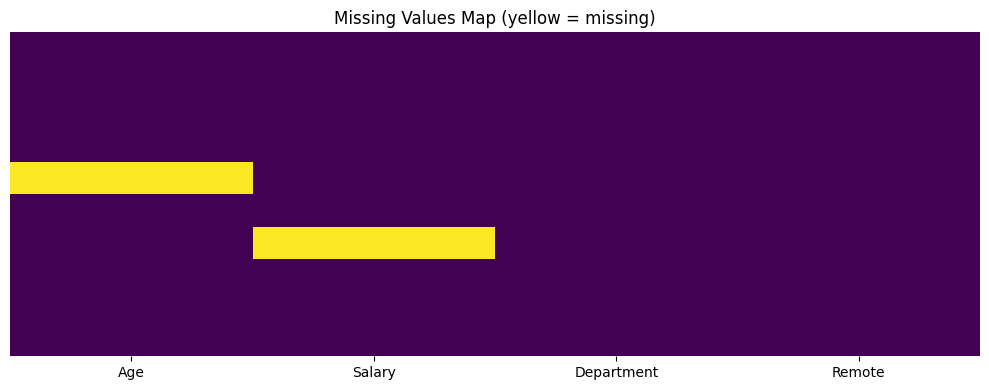


 5b. UNIVARIATE VISUALIZATIONS


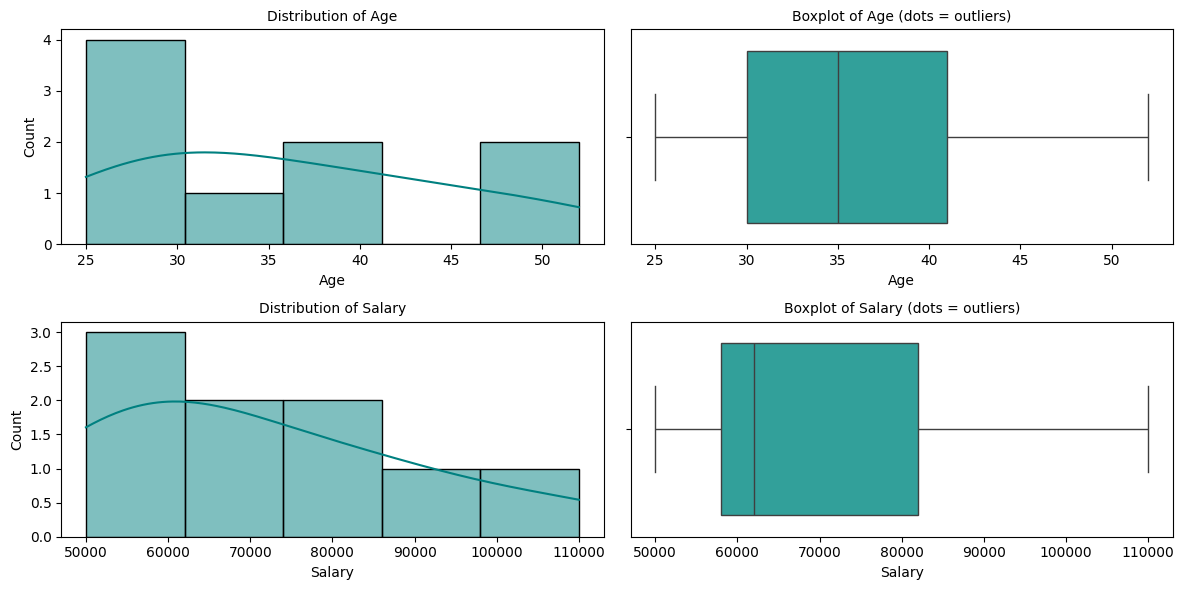

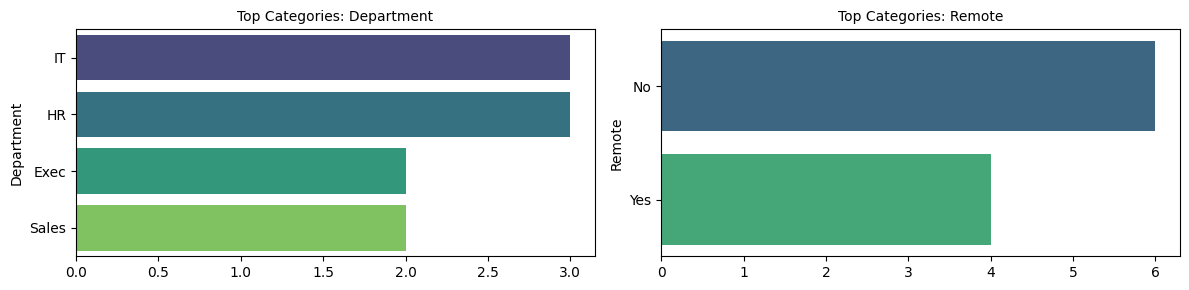


 5c. CORRELATION ANALYSIS


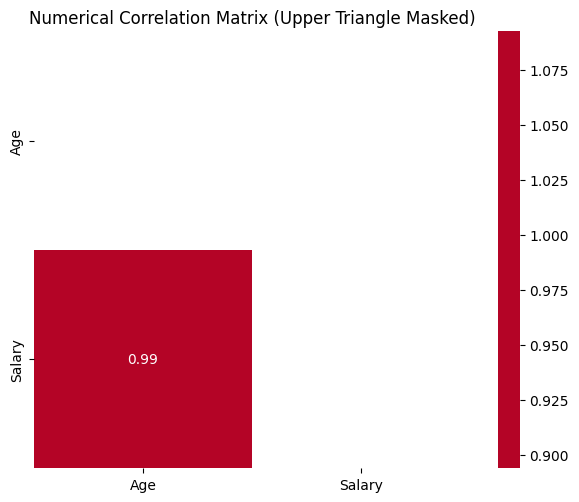

Highly correlated pairs (|r| >= 0.8):
  Age <-> Salary: 0.99

 6. TARGET ANALYSIS: Salary
Correlation with target:
Age    0.993
Name: Salary, dtype: float64

Average Salary by Department:
                mean    median  count
Department                           
Exec        100500.0  100500.0      2
HR           58666.7   62000.0      3
IT           62500.0   62500.0      2
Sales        70000.0   70000.0      2

Average Salary by Remote:
           mean   median  count
Remote                         
No      76500.0  72000.0      6
Yes     61000.0  58000.0      3


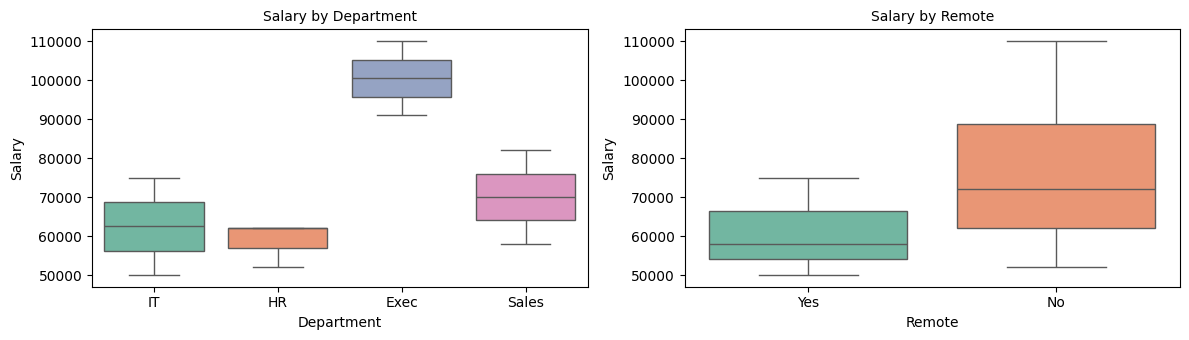


 7. KEY FINDINGS
1. Dataset has 10 rows and 4 columns (2 numerical, 2 categorical).
2. Dataset is small (< 100 rows): statistics and correlations may be unreliable.
3. Column 'Age' has 1 missing values (10.0%) - moderate - impute (fill) carefully.
4. Column 'Salary' has 1 missing values (10.0%) - moderate - impute (fill) carefully.
5. 1 duplicate row(s) found - verify if they are real or errors.
6. 'Age' and 'Salary' are highly correlated (r = 0.99) - possible multicollinearity, you may keep only one.
7. Strongest numeric relationship with 'Salary' is 'Age' (r = 0.99).

Report saved to: eda_output/eda_report.md


In [3]:
pipeline = EDAPipeline(df=data, target_col='Salary', save_dir='eda_output')
pipeline.run_all()

## 3. Or run only the steps you need (method chaining)

In [4]:
EDAPipeline(data).structural_audit().quality_audit().outlier_analysis()


 1. STRUCTURAL AUDIT
Data shape      : 10 rows, 4 columns
Numerical cols  : 2 -> ['Age', 'Salary']
Categorical cols: 2 -> ['Department', 'Remote']
Memory usage    : 0.0013 MB

--- Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Age         9 non-null      float64
 1   Salary      9 non-null      float64
 2   Department  10 non-null     str    
 3   Remote      10 non-null     str    
dtypes: float64(2), str(2)
memory usage: 452.0 bytes

--- First 5 rows ---
    Age    Salary Department Remote
0  25.0   50000.0         IT    Yes
1  30.0   62000.0         HR     No
2  47.0  110000.0       Exec     No
3  35.0   75000.0         IT    Yes
4   NaN   58000.0      Sales    Yes

 2. DATA QUALITY AUDIT
Missing Data Profile:
        Missing Count  Missing Percentage
Age                 1                10.0
Salary              1        